# EXPERIMENT 7
## Implementation of a Simple Autoencoder for Dimensionality Reduction and Feature Learning

**Name:** Saravanan P  
**Roll No.:** 24BAD105  
**Dataset:** MNIST handwritten digits  
**Platform:** Google Colab



## Part A – Dataset Preparation


Name: Saravanan P
Roll No: 24BAD105
Experiment 7: Simple Autoencoder
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8
Number of training samples: 60000
Number of testing samples: 10000

After flattening:
Training shape: (60000, 784)
Testing shape: (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


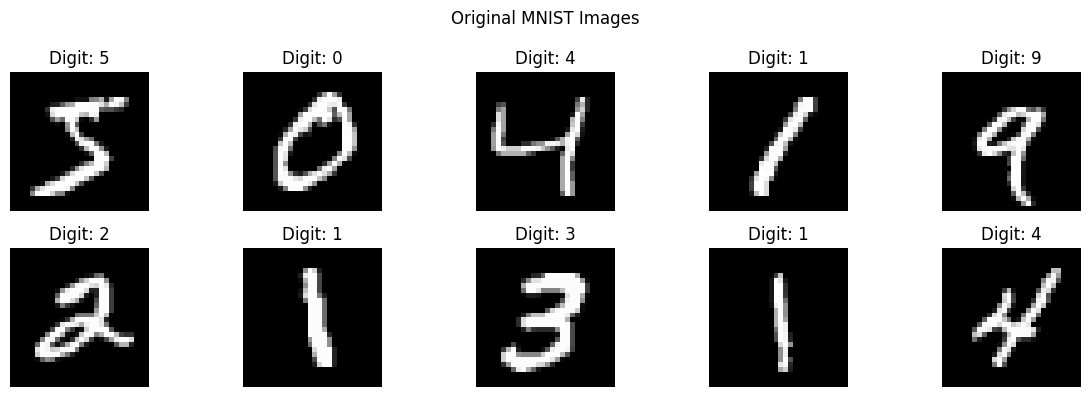

In [1]:
# EXPERIMENT 7 – PART A
# Name: Saravanan P | Roll No: 24BAD105

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers, models
from sklearn.decomposition import PCA

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("Name: Saravanan P")
print("Roll No: 24BAD105")
print("Experiment 7: Simple Autoencoder")

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Explore dataset
print("\nTraining data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Data type:", x_train.dtype)
print("Number of training samples:", len(x_train))
print("Number of testing samples:", len(x_test))

# Normalize pixel values to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten 28 x 28 images into 784-dimensional vectors
x_train_flat = x_train.reshape(x_train.shape[0], 784)
x_test_flat = x_test.reshape(x_test.shape[0], 784)

print("\nAfter flattening:")
print("Training shape:", x_train_flat.shape)
print("Testing shape:", x_test_flat.shape)
print("Minimum pixel value:", x_train_flat.min())
print("Maximum pixel value:", x_train_flat.max())

# Display 10 original sample images
plt.figure(figsize=(12, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Original MNIST Images")
plt.tight_layout()
plt.show()

## Part B – Implementing the Autoencoder Model


In [2]:
# EXPERIMENT 7 – PART B

input_dim = 784
encoding_dim = 32

# -------------------------
# ENCODER
# -------------------------
input_img = layers.Input(shape=(input_dim,), name="encoder_input")
encoded = layers.Dense(128, activation="relu", name="encoder_hidden")(input_img)
latent = layers.Dense(encoding_dim, activation="relu", name="bottleneck")(encoded)
encoder = models.Model(input_img, latent, name="Encoder")

# -------------------------
# DECODER
# -------------------------
latent_input = layers.Input(shape=(encoding_dim,), name="decoder_input")
decoded = layers.Dense(128, activation="relu", name="decoder_hidden")(latent_input)
decoded = layers.Dense(input_dim, activation="sigmoid", name="reconstruction")(decoded)
decoder = models.Model(latent_input, decoded, name="Decoder")

# -------------------------
# COMPLETE AUTOENCODER
# -------------------------
autoencoder_output = decoder(encoder(input_img))
autoencoder = models.Model(input_img, autoencoder_output, name="Autoencoder")

# Compile using Adam optimizer and Mean Squared Error loss
autoencoder.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

print("ENCODER SUMMARY")
encoder.summary()

print("\nDECODER SUMMARY")
decoder.summary()

print("\nCOMPLETE AUTOENCODER SUMMARY")
autoencoder.summary()

ENCODER SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_hidden (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Dense)              │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

## Part C – Model Training and Performance Evaluation


Epoch 1/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0608 - val_loss: 0.0351
Epoch 2/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0275 - val_loss: 0.0217
Epoch 3/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0197 - val_loss: 0.0177
Epoch 4/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0166 - val_loss: 0.0152
Epoch 5/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0146 - val_loss: 0.0138
Epoch 6/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0134 - val_loss: 0.0129
Epoch 7/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0126 - val_loss: 0.0122
Epoch 8/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0119 - val_loss: 0.0116
Epoch 9/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0114 - val_loss: 0.0112
Epoch 10/10
211/211 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.0110 - val_loss: 0.0108

Test reconstruction loss: 0.010470123961567879
Reconstruction MSE: 0.010470124


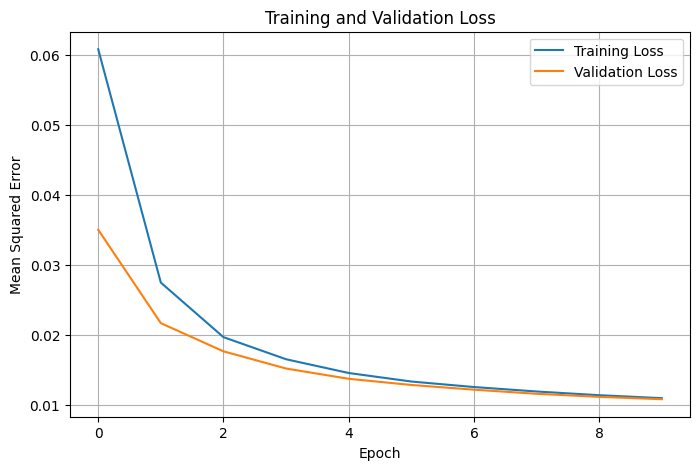

In [3]:
# EXPERIMENT 7 – PART C: TRAINING

history = autoencoder.fit(
    x_train_flat,
    x_train_flat,                 # target is the same as input
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_split=0.1,
    verbose=1
)

# Evaluate on test data
test_loss = autoencoder.evaluate(x_test_flat, x_test_flat, verbose=0)

# Reconstruct test images
reconstructed = autoencoder.predict(x_test_flat, verbose=0)

# Calculate reconstruction Mean Squared Error (MSE)
mse = np.mean(np.square(x_test_flat - reconstructed))

print("\nTest reconstruction loss:", test_loss)
print("Reconstruction MSE:", mse)

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

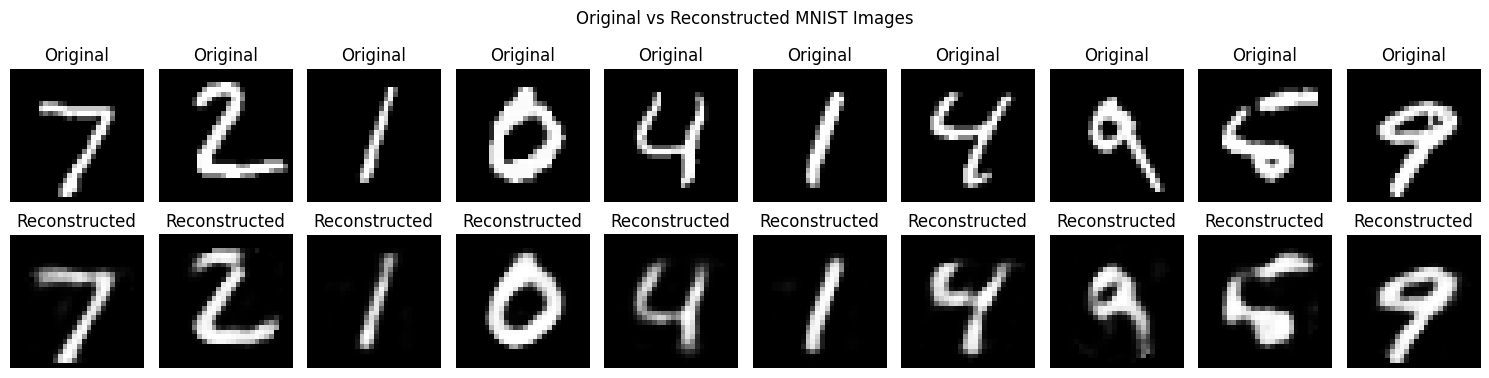

In [4]:
# EXPERIMENT 7 – PART C: ORIGINAL vs RECONSTRUCTED IMAGES

n = 10
plt.figure(figsize=(15, 4))

for i in range(n):
    # Original image
    plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("Original vs Reconstructed MNIST Images")
plt.tight_layout()
plt.show()

## Part D – Dimensionality Reduction, Feature Visualization and Reconstruction


Original data shape: (10000, 784)
Compressed data shape: (10000, 32)
Compression ratio (input dimensions / latent dimensions): 24.5
Dimensionality reduced from 784 to 32


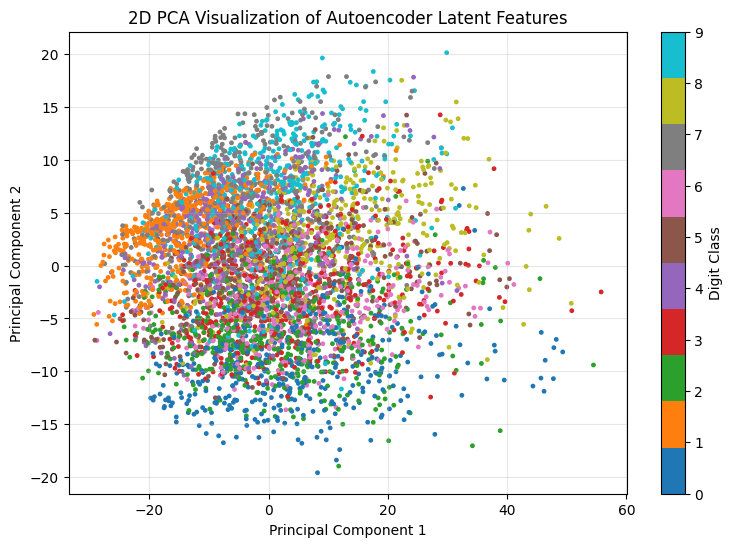

Explained variance ratio: [0.35095876 0.09007468]
Total variance shown in 2D: 0.44103345


In [5]:
# EXPERIMENT 7 – PART D: LATENT REPRESENTATIONS

# Extract compressed features using the trained Encoder
encoded_data = encoder.predict(x_test_flat, verbose=0)

print("Original data shape:", x_test_flat.shape)
print("Compressed data shape:", encoded_data.shape)

compression_ratio = 784 / encoding_dim
print("Compression ratio (input dimensions / latent dimensions):", compression_ratio)
print("Dimensionality reduced from", input_dim, "to", encoding_dim)

# Reduce latent vectors to 2D only for visualization using PCA
sample_count = 5000
pca = PCA(n_components=2, random_state=42)
latent_2d = pca.fit_transform(encoded_data[:sample_count])

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test[:sample_count],
    cmap="tab10",
    s=6
)
plt.colorbar(scatter, label="Digit Class")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA Visualization of Autoencoder Latent Features")
plt.grid(True, alpha=0.3)
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance shown in 2D:", pca.explained_variance_ratio_.sum())

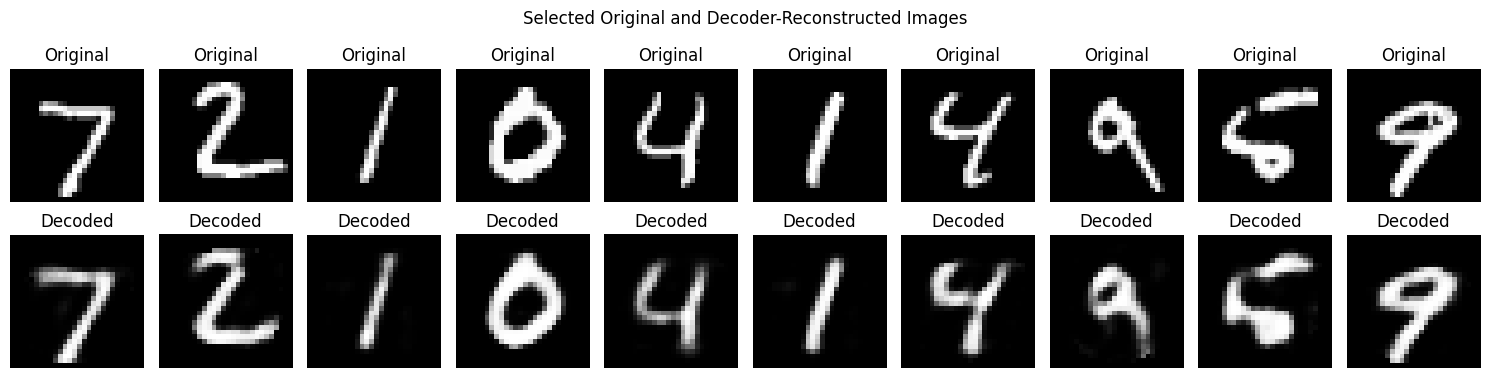

Dimensionality reduction and reconstruction completed successfully.


In [6]:
# EXPERIMENT 7 – PART D: DECODE SELECTED TEST SAMPLES

selected_indices = list(range(10))
selected_latent = encoded_data[selected_indices]

# Reconstruct selected samples using the Decoder
decoded_samples = decoder.predict(selected_latent, verbose=0)

plt.figure(figsize=(15, 4))
for i, index in enumerate(selected_indices):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[index], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Decoder output
    plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_samples[i].reshape(28, 28), cmap="gray")
    plt.title("Decoded")
    plt.axis("off")

plt.suptitle("Selected Original and Decoder-Reconstructed Images")
plt.tight_layout()
plt.show()

print("Dimensionality reduction and reconstruction completed successfully.")